In [23]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

In [78]:
%cd /Users/diana/Desktop/Tommaso/M0S0
#mat_file = 'HFO_pat_61_number_4_thr.mat' # ts for M0K0
#mat_file = 'HFO_pat_40_number_2_thr.mat' # ts for M0S0
#mat_file = 'HFO_pat_1_number_3_thr.mat' # ts for M0R0

/Users/diana/Desktop/Tommaso/M0S0


### Creating spike_trials

In [5]:
spikes_data = sio.loadmat(mat_file)

In [6]:
#import mat73 
import scipy
data = scipy.io.loadmat('erf.mat') 

In [7]:
spikes_data['aligned_spikes'][0]

array([1.        , 0.05078125])

In [8]:
ts = []

for elem in spikes_data["aligned_spikes"]:
    if elem[0] == 4:   # collecting spike ts from channel 19  !!! CHANGE
        ts.append(elem[1])

In [44]:
len(ts)

19

In [22]:
#data["erf_all"][0][0][5].shape # MOSO
data["erf_all"][0][0][0].shape

(84, 76801)

In [23]:
#data_ = data["patientStructFull"]["epochsList"][4]["X_raw"] # segment - 1
data_ = data["erf_all"][0][0][0]

In [24]:
#data_[:,19].shape
data_[0,:].shape

(76801,)

In [46]:
fs = 2048
N_samples = data_[0,:].shape[0]

In [47]:
spike_trials = []
for i in range(len(ts)):
    spike_sample = round(ts[i] * fs);
    #print(spike_sample)
    if (spike_sample-250 >= 1) and (spike_sample+150 <= N_samples):
        start = spike_sample - 250
        end = spike_sample + 150
        waveform = data_[3, :].flatten()[start:end] # CHANNEL
        print(waveform.shape)
        spike_trials.append(waveform)
        
spike_trials = np.array(spike_trials)

(400,)
(400,)
(400,)


In [166]:
#np.savetxt('spike_19_seeg.out', spike_trials, delimiter=',') 

### Analysing spike_trials

In [117]:
#spike_trials = np.loadtxt('/Users/diana/Desktop/spike_1_seeg.out', delimiter=',')  

In [118]:
#spike_trials = spike_trials['spike_trials']

In [80]:
fs = 2048

In [81]:
#spike_trials = sio.loadmat('/Users/diana/Desktop/spike_trials.mat') 

In [82]:
spike_trials = np.loadtxt('spike_trials.csv', delimiter=',')
print(spike_trials.shape)  

(197, 2001)


197 waveforms, 2001 samples


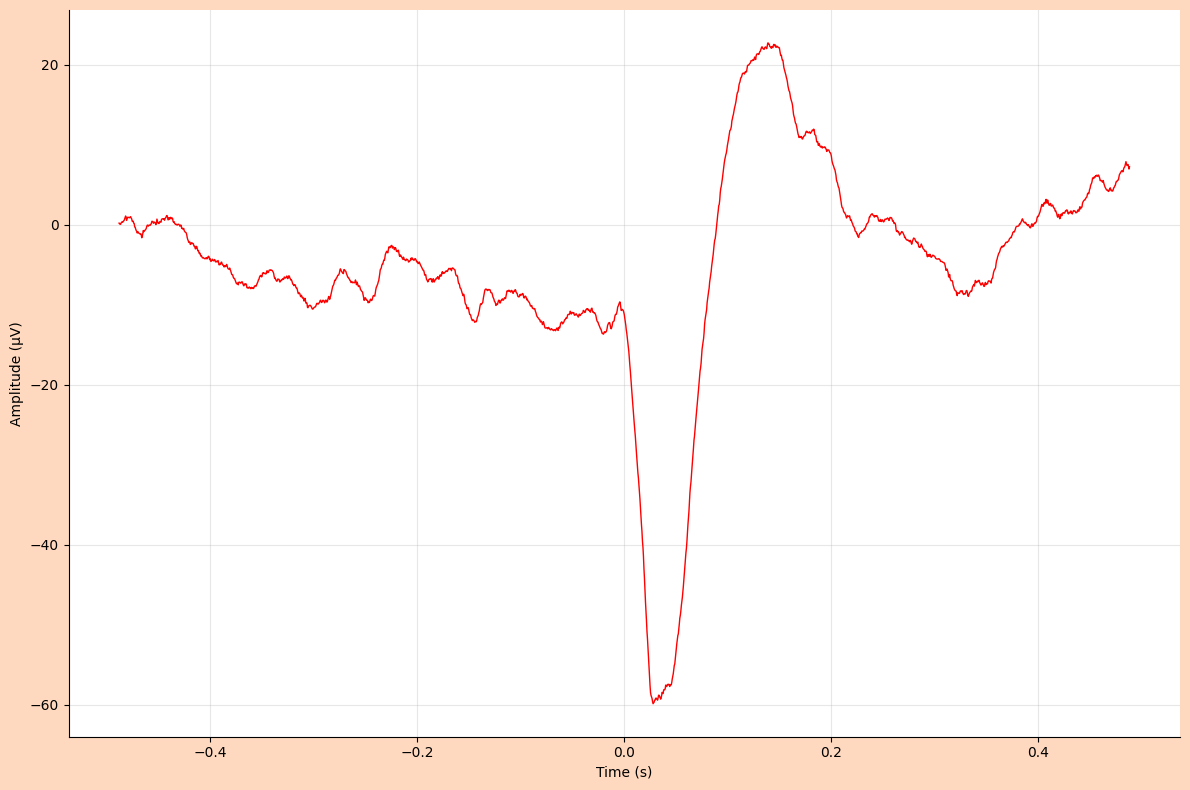

In [83]:
def plot_spike_waveforms(spike_trials, fs=fs, title="Spikes sEEG"):

    fig, ax = plt.subplots(figsize=(12, 8))   
    n_spikes, n_samples = spike_trials.shape
    print(f"{n_spikes} waveforms, {n_samples} samples")

    time = np.arange(-1000, 1001) / fs
    x_label = "Time (s)"

    average_waveform = np.mean(spike_trials, axis=0)
    """
    for i in range(n_spikes):
        if max(abs(spike_trials[i, :]-average_waveform)) < 200:
            ax.plot(time, spike_trials[i, :], 
                color='gray', 
                alpha=0.3, 
                linewidth=0.5)
    """

    average_waveform = np.mean(spike_trials, axis=0)
    #print(average_waveform.shape)
    #print(average_waveform)
    
    ax.plot(time, average_waveform, 
        color='red', 
        linewidth=1)

    ax.set_xlabel(x_label)
    ax.set_ylabel("Amplitude (µV)")
    #ax.set_title(title)
    ax.grid(True, alpha=0.3)

    ax.spines['top'].set_visible(False) # removes the lines
    ax.spines['right'].set_visible(False)

    #ax.set_facecolor((0.8, 0.9, 1.0))          # background inside the plot area
    #fig.set_facecolor((0.8, 0.9, 1.0))         # background around the plot (figure)
    fig.set_facecolor((1.0, 0.85, 0.75))
    fig.subplots_adjust(left=0.25, right=0.75, top=0.85, bottom=0.15)  # bigger margins = wider frame

    plt.tight_layout()
    return fig, ax

#fig, ax = plot_spike_waveforms(spike_trials, fs=fs, title="sEEG spike")
fig, ax = plot_spike_waveforms(spike_trials, fs=fs, title="sEEG spike")
plt.show()

In [84]:
def normalize_epoch(epoch):
    min_val = np.min(epoch)
    max_val = np.max(epoch)
    normalized = 2 * (epoch - min_val) / (max_val - min_val) - 1
    return normalized

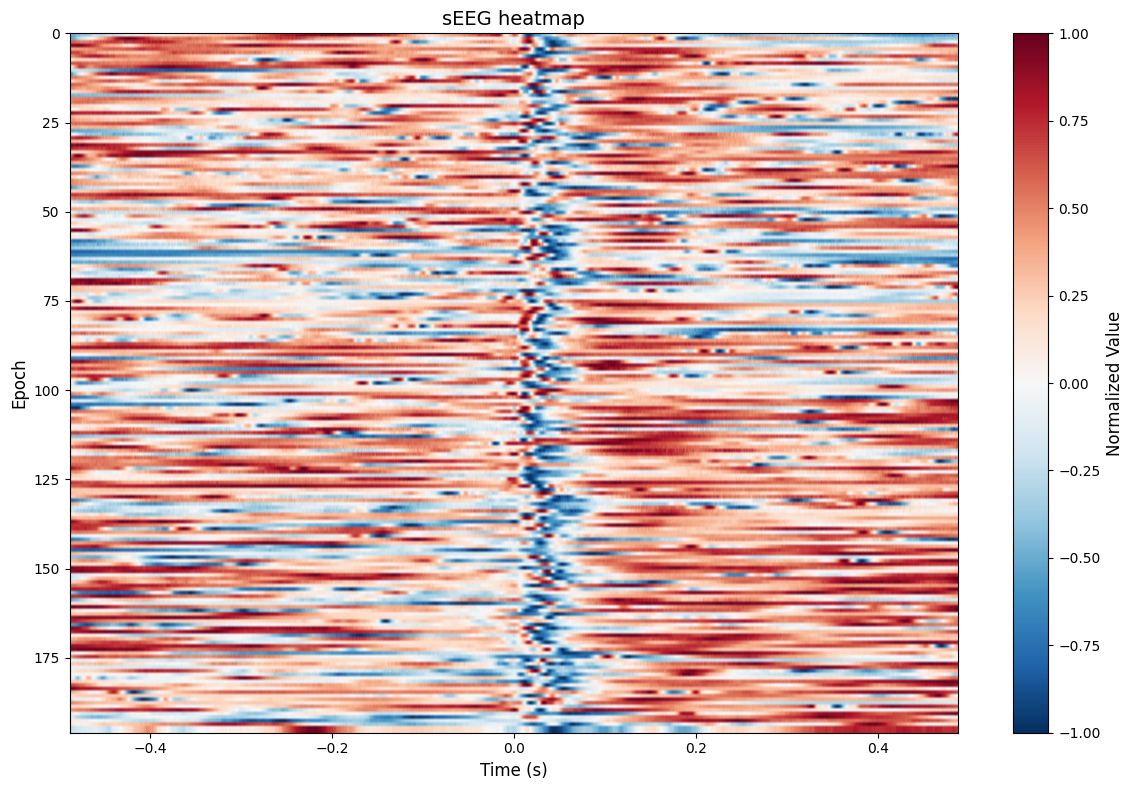

In [85]:
data_normalized = np.array([normalize_epoch(row) for row in spike_trials])
time_points =  np.arange(-1000, 1001) / fs
epoch_numbers = np.arange(spike_trials.shape[0])
plt.figure(figsize=(12, 8))

im = plt.imshow(data_normalized, 
                aspect='auto', 
                cmap='RdBu_r', 
                extent=[time_points[0], time_points[-1], epoch_numbers[-1], epoch_numbers[0]],
                vmin=-1, vmax=1)

plt.xlabel('Time (s)', fontsize=12)
plt.ylabel('Epoch', fontsize=12)
plt.title('sEEG heatmap', fontsize=14)

cbar = plt.colorbar(im)
cbar.set_label('Normalized Value', fontsize=12)
plt.tight_layout()
plt.show()

In [89]:
# find the sample index closest to t = 0.01s
time_points = np.arange(-1000, 1001) / fs
target_time = 0.015
idx_t = np.argmin(np.abs(time_points - target_time))
print(f"Using sample at t={time_points[idx_t]:.4f}s (target was {target_time}s)")

# normalize all epochs first (so 'reddest' is comparable across epochs)
data_normalized_all = np.array([normalize_epoch(row) for row in spike_trials])

# rank epochs by value at that time point, descending (most positive = reddest)
values_at_t = data_normalized_all[:, idx_t]
n_random = 20
top_idx = np.argsort(values_at_t)[:n_random] #[::-1]
top_idx.sort()  # optional: keep them in original epoch order for the plot

spike_subset = spike_trials[top_idx, :]

Using sample at t=0.0151s (target was 0.015s)


197 waveforms, 2001 samples


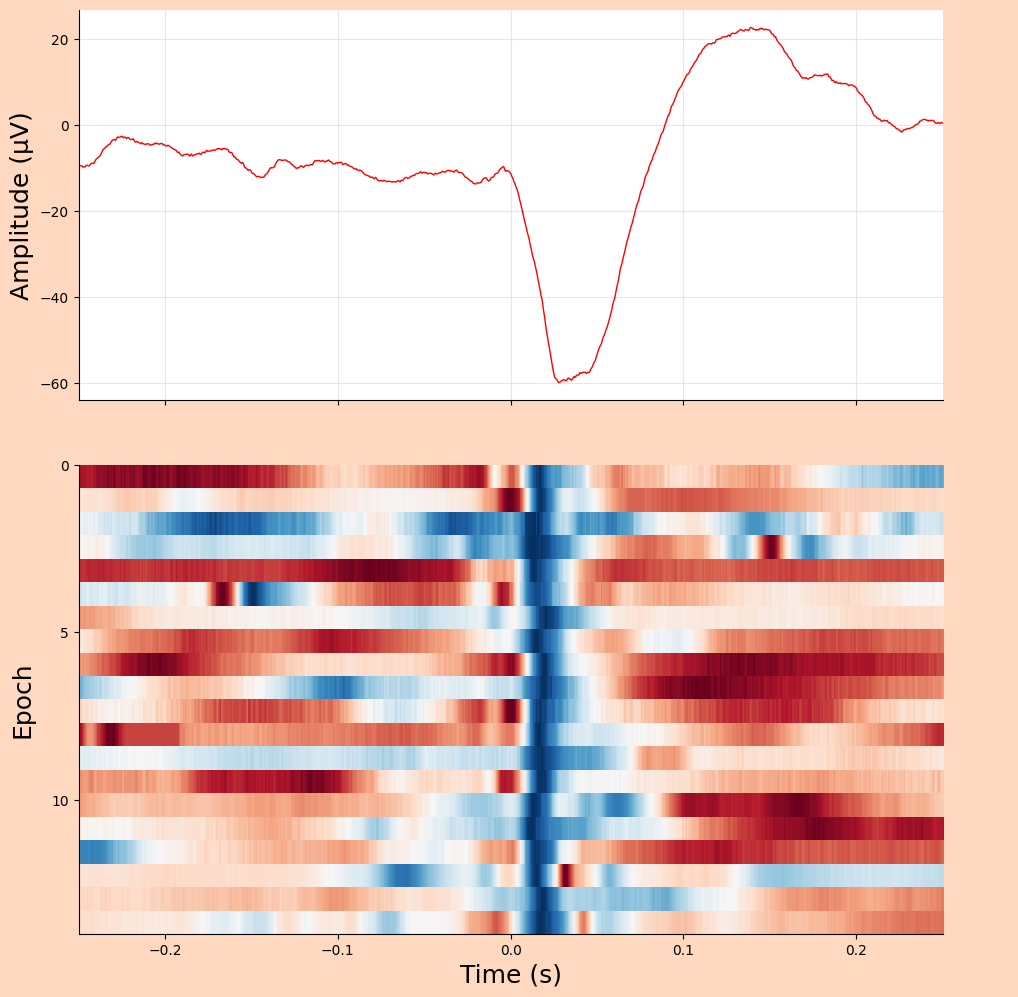

In [90]:
import matplotlib.gridspec as gridspec

def plot_spike_summary(spike_trials, fs=fs, title="sEEG spike", n_random=20, seed=None):
    n_spikes, n_samples = spike_trials.shape
    print(f"{n_spikes} waveforms, {n_samples} samples")

    time = np.arange(-1000, 1001) / fs
    x_label = "Time (s)"

    fig = plt.figure(figsize=(12, 12))
    gs = gridspec.GridSpec(2, 2, width_ratios=[20, 1], height_ratios=[1, 1.2],
                            hspace=0.15, wspace=0.05)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
    cax = fig.add_subplot(gs[1, 1])
    cax.axis('off')

    # --- Top: average waveform (still uses ALL spikes) ---
    average_waveform = np.mean(spike_trials, axis=0)

    ax1.plot(time, average_waveform, 
             color='red', 
             linewidth=1)

    ax1.set_ylabel("Amplitude (µV)", fontsize=18)
    #yticks = np.arange(400, -850, -400)
    #ax1.set_yticks(yticks)
    #ax1.set_title(title, fontsize=16)
    ax1.grid(True, alpha=0.3)

    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.tick_params(labelbottom=False)

    # --- Bottom: heatmap on 20 random epochs ---
    #rng = np.random.default_rng(seed)
    #random_idx = rng.choice(n_spikes, size=min(n_random, n_spikes), replace=False)
    #random_idx.sort()  # optional: keeps original epoch order in the plot

    #spike_subset = spike_trials[random_idx, :]
    data_normalized = np.array([normalize_epoch(row) for row in spike_subset])
    time_points = np.arange(-1000, 1001) / fs
    epoch_numbers = np.arange(15)

    im = ax2.imshow(data_normalized, 
                     aspect='auto', 
                     cmap='RdBu_r', 
                     interpolation='nearest', 
                     extent=[time_points[0], time_points[-1], epoch_numbers[-1], epoch_numbers[0]],
                     vmin=-1, vmax=1)


    ax2.set_xlabel(x_label, fontsize=18)
    ax2.set_ylabel('Epoch', fontsize=18)
    #ax2.set_title('sEEG heatmap', fontsize=16)
    
    yticks = np.arange(0, 15, 5)
    ax2.set_yticks(yticks)

    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    fig.set_facecolor((1.0, 0.85, 0.75))
    ax1.set_xlim(-0.25, 0.25)
    fig.align_ylabels([ax1, ax2])

    return fig, (ax1, ax2)


fig, (ax1, ax2) = plot_spike_summary(spike_trials, fs=fs, title="sEEG spike")
plt.show()

## Spike for MEG

In [35]:
%pwd

'/Users/diana/Desktop/Tommaso/M0R0'

In [68]:
meg_file = "meg_grad_2_noav.out"
spike_meg = np.loadtxt(meg_file)

In [69]:
#meg_file = "meg_grad_2_noav.out"
#spike_meg = np.loadtxt(meg_file)

In [70]:
fs=2048

In [71]:
spike_meg.shape

(15, 501)

In [72]:
from scipy.signal import savgol_filter

avg = spike_meg.mean(axis=0)  # shape (501,)
smooth = savgol_filter(avg, window_length=19, polyorder=3) 

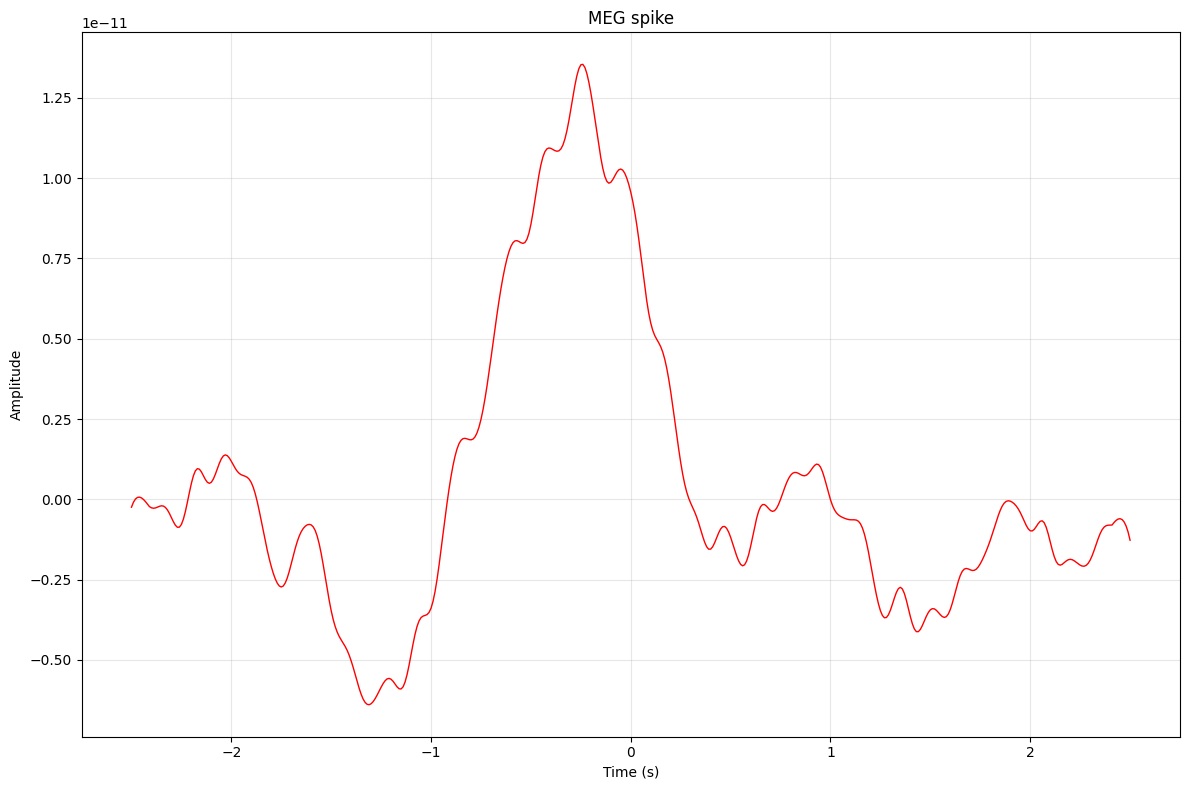

In [73]:
fig, ax = plt.subplots(figsize=(12, 8))   
n_samples = spike_meg[0].shape

time = np.arange(-250, 251)/ 100
x_label = "Time (s)"
    
ax.plot(time, smooth, 
            color='red', 
            linewidth=1)
    
ax.set_xlabel(x_label)
ax.set_ylabel("Amplitude")
ax.set_title("MEG spike")
ax.grid(True, alpha=0.3)
plt.tight_layout()

In [74]:
#meg_file = "meg_mag_0_noav.out"
#spike_meg = np.loadtxt(meg_file)

In [75]:
spike_meg.shape

(15, 501)

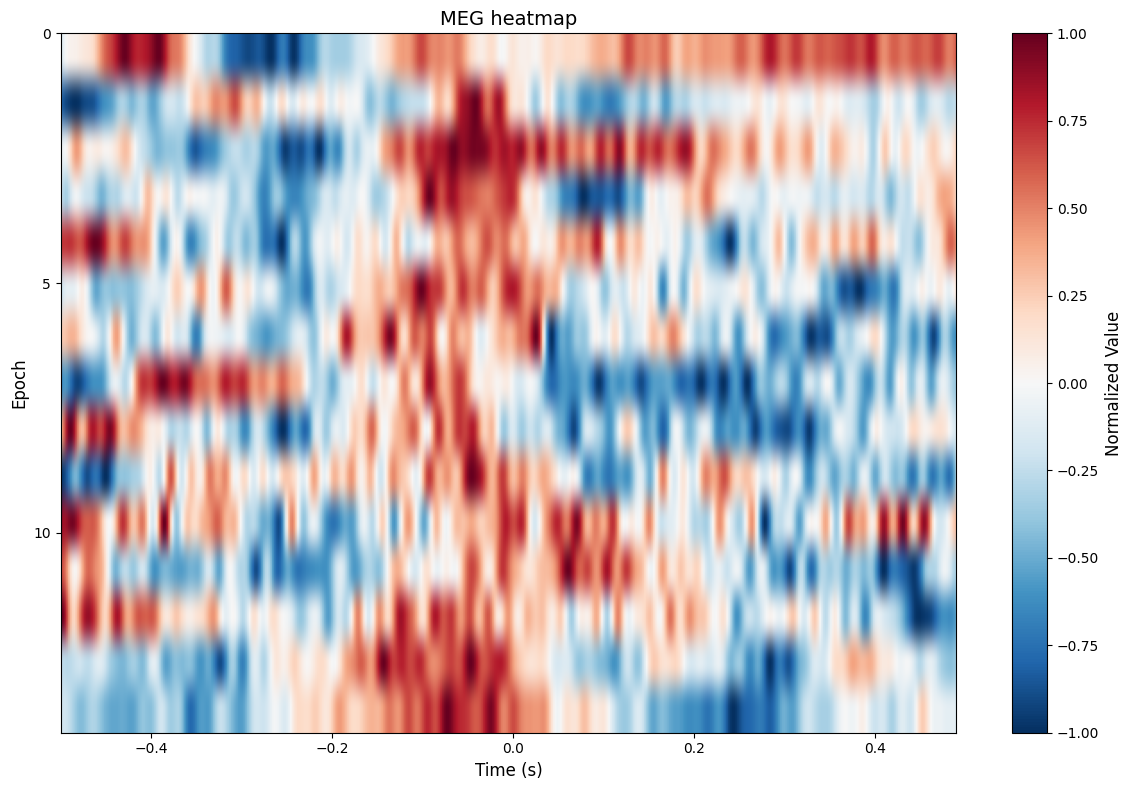

In [76]:
data_normalized = np.array([normalize_epoch(row) for row in spike_meg])
time = np.arange(-50, 50) / 100
n_epochs = spike_meg.shape[0]
epoch_numbers = np.arange(n_epochs)

plt.figure(figsize=(12, 8))

im = plt.imshow(data_normalized,
                 aspect='auto',
                 cmap='RdBu_r',
                 extent=[time[0], time[-1], epoch_numbers[-1], epoch_numbers[0]],
                 vmin=-1, vmax=1)

plt.xlabel('Time (s)', fontsize=12)
plt.ylabel('Epoch', fontsize=12)
plt.title('MEG heatmap', fontsize=14)

# y-axis ticks every 5 epochs
yticks = np.arange(0, n_epochs, 5)
plt.yticks(yticks)

cbar = plt.colorbar(im)
cbar.set_label('Normalized Value', fontsize=12)
plt.tight_layout()
plt.show()

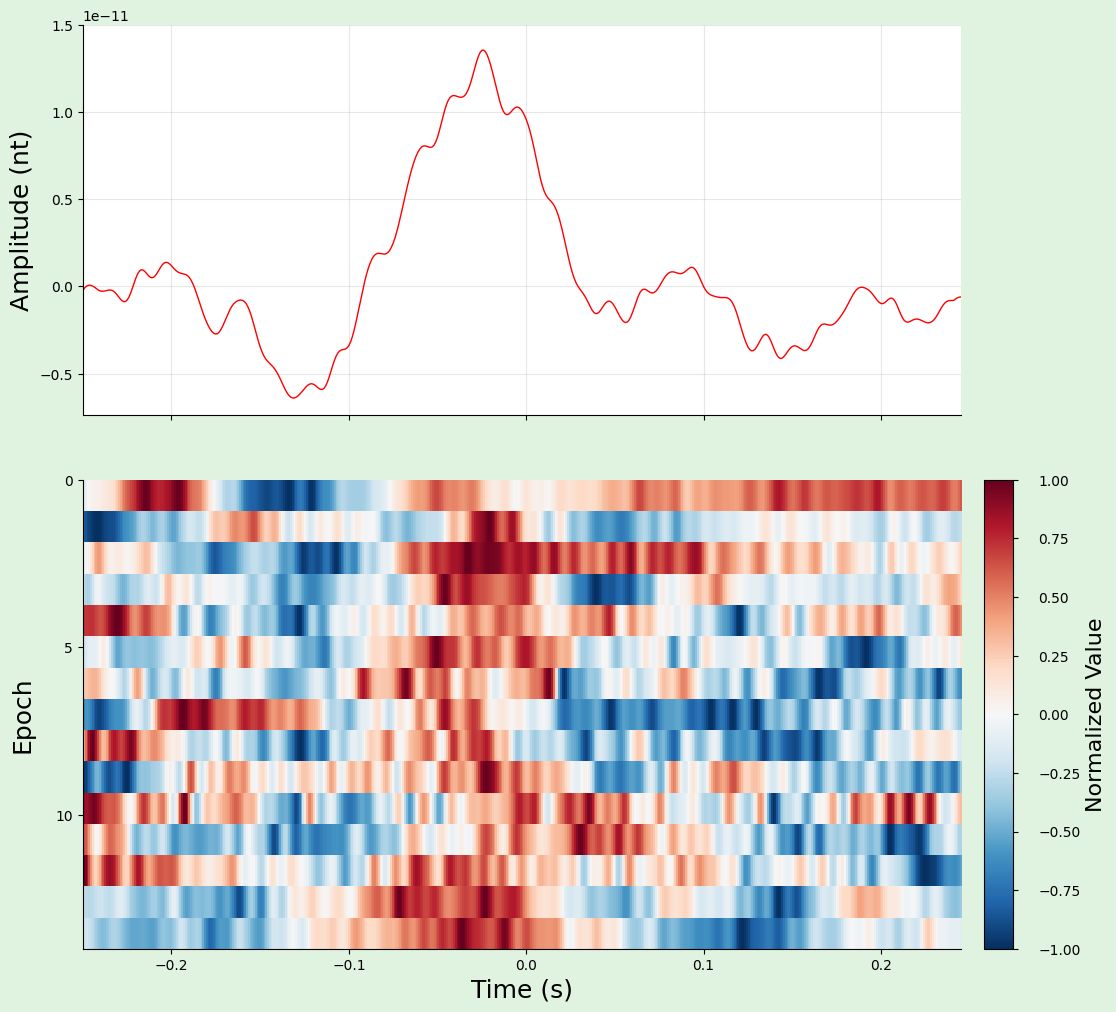

In [77]:
import matplotlib.gridspec as gridspec

def plot_meg_summary(spike_meg, smooth, title="MEG spike"):
    n_epochs, n_samples = spike_meg.shape

    fig = plt.figure(figsize=(12, 12))
    gs = gridspec.GridSpec(2, 2, width_ratios=[30, 1], height_ratios=[1, 1.2],
                            hspace=0.15, wspace=0.05)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
    cax = fig.add_subplot(gs[1, 1])

    # --- Top: average waveform ---
    time_wave = np.arange(-250, 251) / 1000

    ax1.plot(time_wave, smooth, 
             color='red', 
             linewidth=1)

    ax1.set_ylabel("Amplitude (nt)", fontsize=18)
    #ax1.set_title(title, fontsize=16)
    ax1.grid(True, alpha=0.3)

    yticks = np.arange(1.5e-11, -0.75e-11, -0.5e-11)
    ax1.set_yticks(yticks)

    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.tick_params(labelbottom=False)

    # --- Bottom: heatmap ---
    data_normalized = np.array([normalize_epoch(row) for row in spike_meg])
    time_heatmap = np.arange(-50, 50) / 200
    epoch_numbers = np.arange(n_epochs)

    im = ax2.imshow(data_normalized,
                     aspect='auto',
                     cmap='RdBu_r',
                     interpolation='nearest',
                     extent=[time_heatmap[0], time_heatmap[-1], epoch_numbers[-1], epoch_numbers[0]],
                     vmin=-1, vmax=1)

    ax2.set_xlabel('Time (s)', fontsize=18)
    ax2.set_ylabel('Epoch', fontsize=18)
   # ax2.set_title('MEG heatmap', fontsize=18)

    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    yticks = np.arange(0, n_epochs, 5)
    ax2.set_yticks(yticks)

    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label('Normalized Value', fontsize=16)
    cax.tick_params(pad=15)

    fig.set_facecolor((0.88, 0.95, 0.88))
    fig.align_ylabels([ax1, ax2])

    return fig, (ax1, ax2)


fig, (ax1, ax2) = plot_meg_summary(spike_meg, smooth, title="MEG spike")
plt.show()